# Singapore HDB Resale Market Analysis

This notebook builds on the initial data exploration by examining the factors associated with HDB resale prices, including flat characteristics, location, size, storey level, lease duration and transaction period. 

## 1. Setup and Data Preparation

The cleaned up HDB resale dataset from the intial exploration is loaded and prepared for further analysis. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/hdb_resale_cleaned.csv")

df.head()

,_id,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,remaining_lease_numeric,price_per_sqm
0,1,2017-01-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0,61.333333,5272.727273
1,2,2017-01-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0,60.583333,3731.343284
2,3,2017-01-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0,62.416667,3910.447761
3,4,2017-01-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0,62.000000,3897.058824
4,5,2017-01-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0,62.416667,3955.223881


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (240807, 14)


In [4]:
df.columns

Index(['_id', 'month', 'town', 'flat_type', 'block', 'street_name',
       'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date',
       'remaining_lease', 'resale_price', 'remaining_lease_numeric',
       'price_per_sqm'],
      dtype='str')

### 1.1 Data Type Validation 

In [5]:
df["month"] = pd.to_datetime(df["month"])

df.dtypes

_id                                 int64
month                      datetime64[us]
town                                  str
flat_type                             str
block                                 str
street_name                           str
storey_range                          str
floor_area_sqm                    float64
flat_model                            str
lease_commence_date                 int64
remaining_lease                       str
resale_price                      float64
remaining_lease_numeric           float64
price_per_sqm                     float64
dtype: object

In [6]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (240807, 14)
Missing values: 0
Duplicate rows: 0


## 2. Price Drivers 

This section examines how key flat characteristics are associated with HDB resale prices. The analysis focuses on floor area, flat type, storey range, remaining lease and location. 

### 2.1 Floor Area vs Resale Price 

This analysis examines the relationship between flat size and resale price. A scatter plot is used to assess whether larger floor areas are generally asswociated with higher resale prices. 

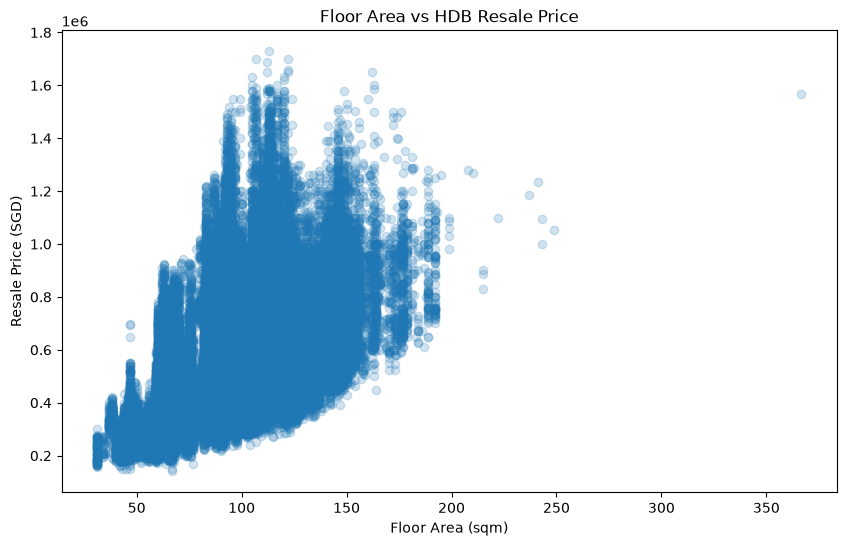

In [7]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["floor_area_sqm"],
    df["resale_price"],
    alpha=0.2
)

plt.title("Floor Area vs HDB Resale Price")
plt.xlabel("Floor Area (sqm)")
plt.ylabel("Resale Price (SGD)")

plt.show()

#### 2.1.1 Trend Line 

A linear trend line is added to summarize the overall direction of the relationship between floor area and resale price. 

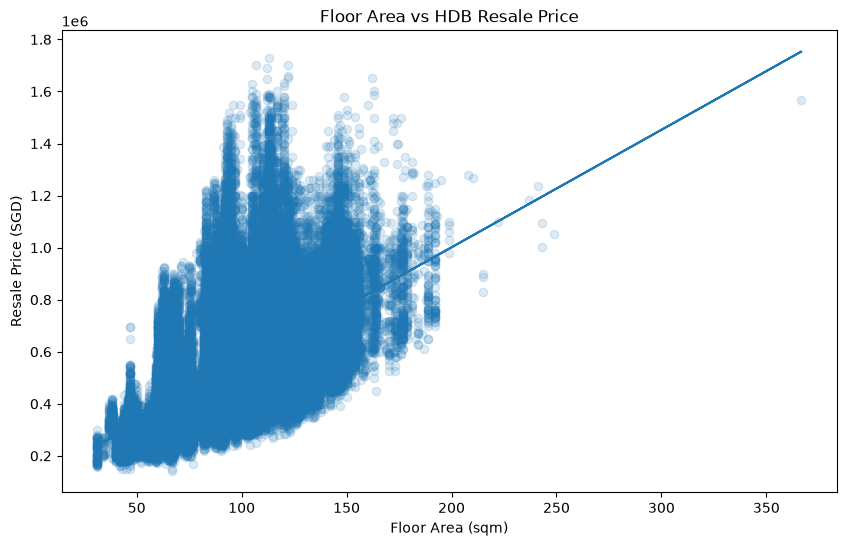

In [8]:
import numpy as np

x = df["floor_area_sqm"]
y = df["resale_price"]

slope, intercept = np.polyfit(x, y, 1)

trend_line = slope * x + intercept

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.15
)

plt.plot(
    x,
    trend_line
)

plt.title("Floor Area vs HDB Resale Price")
plt.xlabel("Floor Area (sqm)")
plt.ylabel("Resale Price (SGD)")

plt.show()

#### 2.1.2 Correlation 

The Pearson correlation coefficient is calculated to quantify the strength and direction of the linear relationship between the floor area and resale price. 

In [9]:
floor_area_correlation = df[
    ["floor_area_sqm", "resale_price"]
].corr()

floor_area_correlation

,floor_area_sqm,resale_price
floor_area_sqm,1.00000,0.56301
resale_price,0.56301,1.00000


**Key finding:** Floor area has a moderate positive correlation with resale price (r = 0.563). This indicates that larger flats generally transact at higher prices, although the spread of transactions around the trend line suggests that other factors also contribute to resale prices.

### 2.2 Flat Type vs Resale Price 

This analysis compares median resale prices across different HDB flat types. The median is used to reduce the influence of unusually high or low transactions. 

In [10]:
flat_type_prices = (
    df.groupby("flat_type")["resale_price"]
    .median()
    .sort_values(ascending=False)
)

flat_type_prices

flat_type
MULTI-GENERATION    848000.0
EXECUTIVE           728000.0
5 ROOM              615000.0
4 ROOM              511000.0
3 ROOM              360000.0
2 ROOM              315000.0
1 ROOM              212500.0
Name: resale_price, dtype: float64

#### 2.2.1 Median Resale Price by FLat Type 

A bar chart is used to compare meidan resale priices across flat types. 

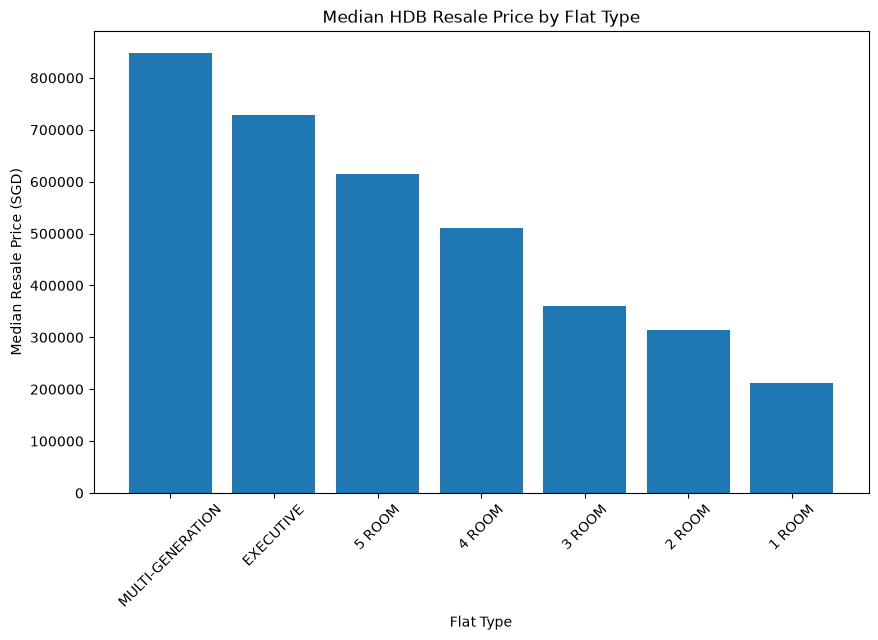

In [11]:
plt.figure(figsize=(10, 6))

plt.bar(
    flat_type_prices.index,
    flat_type_prices.values
)

plt.title("Median HDB Resale Price by Flat Type")
plt.xlabel("Flat Type")
plt.ylabel("Median Resale Price (SGD)")
plt.xticks(rotation=45)

plt.show()

**Key finding:** Median resale prices vary substantially across flat types. Multi-Generation and Executive flats have the highest median resale prices in. the dataset, while 1-Room and 2-Room flats have the lowest. This indicates that flat type is an important characteristic associated with differences in resale prices. 

### 2.3 Storey Range vs Resale Price 

This analysis examines how median resale pricces vary across different storey ranges. Story range is treated as a categorical variable because the dataset records transactions in predeffined floor bands. 

In [12]:
storey_prices = (
    df.groupby("storey_range")["resale_price"]
    .median()
)

storey_prices

storey_range
01 TO 03     455000.0
04 TO 06     475000.0
07 TO 09     490000.0
10 TO 12     505000.0
13 TO 15     550000.0
16 TO 18     593000.0
19 TO 21     680000.0
22 TO 24     710000.0
25 TO 27     770000.0
28 TO 30     860000.0
31 TO 33     900000.0
34 TO 36     900000.0
37 TO 39     920000.0
40 TO 42     980000.0
43 TO 45    1119000.0
46 TO 48    1124000.0
49 TO 51    1228000.0
Name: resale_price, dtype: float64

#### 2.3.1 Median Resale Price by Storey Range 

A line chart is used to visualize the progression of median resale prices across ordered storey ranges. 

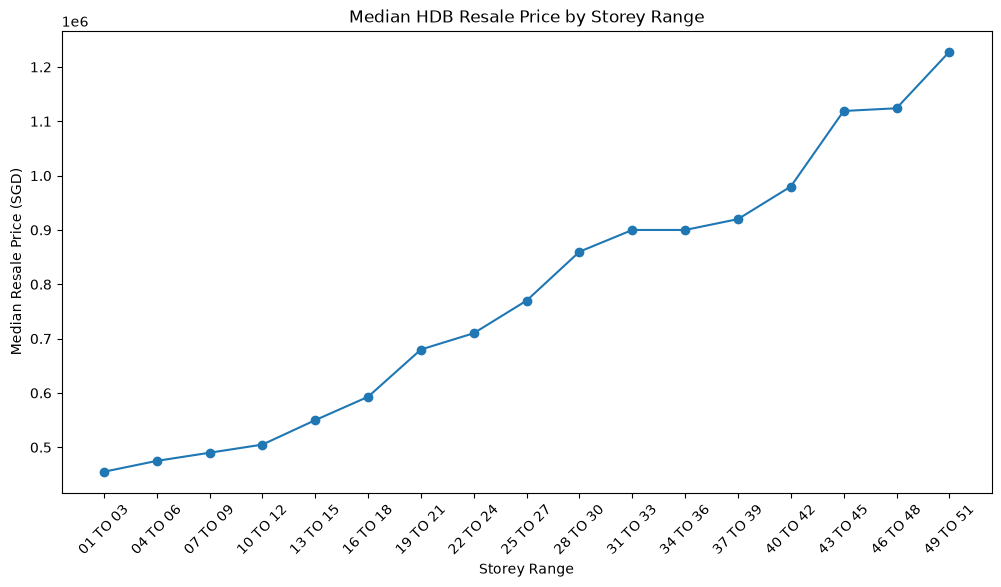

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(
    storey_prices.index,
    storey_prices.values,
    marker="o"
)

plt.title("Median HDB Resale Price by Storey Range")
plt.xlabel("Storey Range")
plt.ylabel("Median Resale Price (SGD)")
plt.xticks(rotation=45)

plt.show()

**Key finding:** Median resale prices generally increase higher storey ranges, rising from $455,000 for transactions in the 01-03 range to $1,228,000 for transactions in the 49-51 range. This indicates a positive association between storey range and resale price in the dataset. However, storey range may also reflect other characteristics such as location, building type or flat size. Thus, this relationship should not be interpreted as a casual effect. 

### 2.4 Remaining Lease vs Resale Price 

This analysis examines the relationship between remaining lease duration and resale price. Remaining lease is represented as an approxiamte number of years to allow for numerical analysis. 

In [14]:
lease_correlation = df[
    ["remaining_lease_numeric", "resale_price"]
].corr()

lease_correlation

,remaining_lease_numeric,resale_price
remaining_lease_numeric,1.000000,0.300027
resale_price,0.300027,1.000000


#### 2.4.1 Median Resale Price by Remaining Lease 

To make the relationship easier to interpret, transactions are grouped by rounded remainig lease years and the median resale price is calculated for each group. 

In [15]:
lease_prices = (
    df.groupby(
        df["remaining_lease_numeric"].round()
    )["resale_price"]
    .median()
    .reset_index()
)

lease_prices.head()

,remaining_lease_numeric,resale_price
0,39.0,316500.0
1,40.0,329000.0
2,41.0,340000.0
3,42.0,333000.0
4,43.0,342000.0


#### 2.4.2 Visualizing the Relationship 

A line chart is used to show how median resale prices vary across different remaining lease durations. 

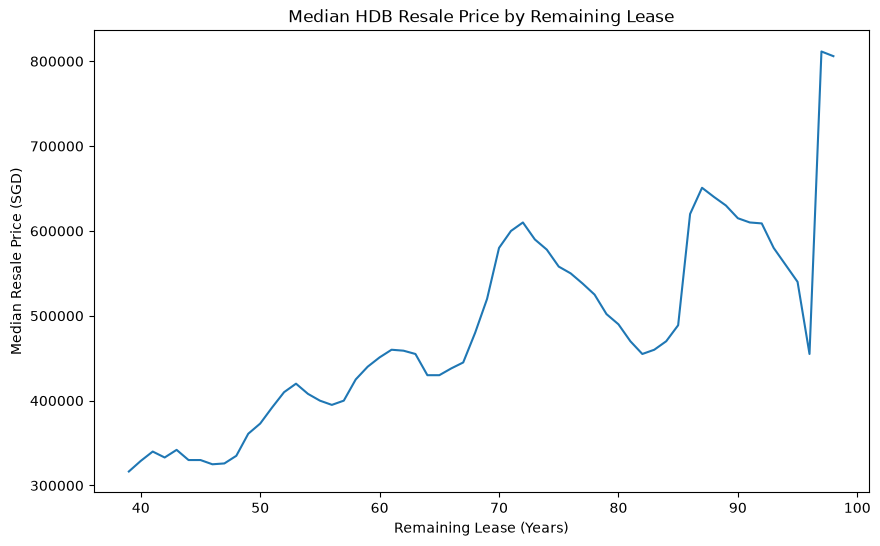

In [16]:
plt.figure(figsize=(10, 6))

plt.plot(
    lease_prices["remaining_lease_numeric"],
    lease_prices["resale_price"]
)

plt.title("Median HDB Resale Price by Remaining Lease")
plt.xlabel("Remaining Lease (Years)")
plt.ylabel("Median Resale Price (SGD)")

plt.show()

**Key finding:** Remaining lease has a positive but modest association with resale price (r = 0.300). Flats with longer remaing leases generally tend to have higher resale prices. However, lease duration alone does not explain the differences in resale prices. Other factors inlcuding flat size, flat type, location, storey range and transaction period also contribute to variation in resale prices.

### 2.5 Town vs Resale Price

This analysis examines how resale prices vary across different HDB towns. Median resale price is used to compare typical transaction values while reducing the influence of unusually high or low transactions. 

In [17]:
town_prices = (
    df.groupby("town")["resale_price"]
    .median()
    .sort_values(ascending=False)
)

town_prices

town
BUKIT TIMAH        792500.0
BISHAN             700000.0
QUEENSTOWN         675000.0
BUKIT MERAH        662000.0
PASIR RIS          580000.0
CENTRAL AREA       575000.0
KALLANG/WHAMPOA    575000.0
TAMPINES           552000.0
SERANGOON          535000.0
PUNGGOL            535000.0
SENGKANG           525000.0
TOA PAYOH          515000.0
SEMBAWANG          505000.0
HOUGANG            500000.0
CLEMENTI           500000.0
MARINE PARADE      495000.0
CHOA CHU KANG      495000.0
BUKIT PANJANG      488000.0
BUKIT BATOK        485000.0
WOODLANDS          470000.0
JURONG WEST        463000.0
GEYLANG            460000.0
JURONG EAST        450000.0
BEDOK              435888.0
YISHUN             435000.0
ANG MO KIO         420000.0
Name: resale_price, dtype: float64

#### 2.5.1 Median Resale Price by Town 

A horizontal bar chart is used to compare median resale prices across HDB towns. Towns are ordered from highest to lowest median resale price to make differences easier to compare. 

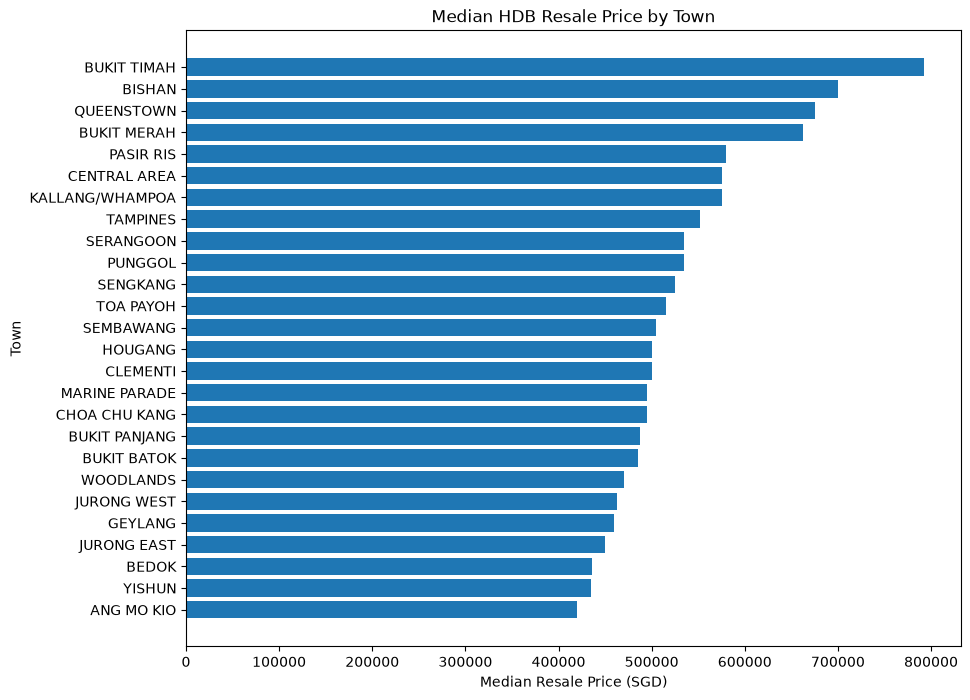

In [18]:
plt.figure(figsize=(10, 8))

plt.barh(
    town_prices.index[::-1],
    town_prices.values[::-1]
)

plt.title("Median HDB Resale Price by Town")
plt.xlabel("Median Resale Price (SGD)")
plt.ylabel("Town")

plt.show()

**Key finding:** Median resale prices vary considerably across HDB towns. In this dataset, Bukit Timah has the highest median resale price at $792,500 while Ang Mo Kio has the lowest at $420,000. This indicates that location is associated with substantial differences in resale prices. However, town-level differences may also reflect other factors such as flat type, floor area, storey range and the mix of transactions within each town. 

### 2.5.2 Price per Square Metre by Town 

Comparing resale price per square metre provides a size-adjusted view of differences across HDB towns. Median price per square metre is used to reduce the influence of unusually high or low transactions. 

In [19]:
town_price_per_sqm = (
    df.groupby("town")["price_per_sqm"]
    .median()
    .sort_values(ascending=False)
)

town_price_per_sqm

town
CENTRAL AREA       7710.843373
QUEENSTOWN         7537.414966
BUKIT MERAH        6982.758621
BUKIT TIMAH        6792.156120
BISHAN             6428.571429
MARINE PARADE      6341.463415
KALLANG/WHAMPOA    6276.923077
TOA PAYOH          5801.980198
CLEMENTI           5791.044776
PUNGGOL            5741.071429
GEYLANG            5661.086987
SERANGOON          5640.280262
TAMPINES           5384.615385
BUKIT BATOK        5343.283582
SENGKANG           5315.315315
SEMBAWANG          5297.297297
ANG MO KIO         5286.692759
HOUGANG            5250.000000
BEDOK              5169.230769
BUKIT PANJANG      4927.521008
JURONG EAST        4925.373134
YISHUN             4923.076923
PASIR RIS          4905.660377
CHOA CHU KANG      4713.114754
WOODLANDS          4636.363636
JURONG WEST        4591.643312
Name: price_per_sqm, dtype: float64

#### 2.5.3 Median Price per Square Metre by Town

A horizontal bar chart is used to compare median resale price per square metre across HDB towns. This provides a size-adjusted comparison of resale values between locations. 

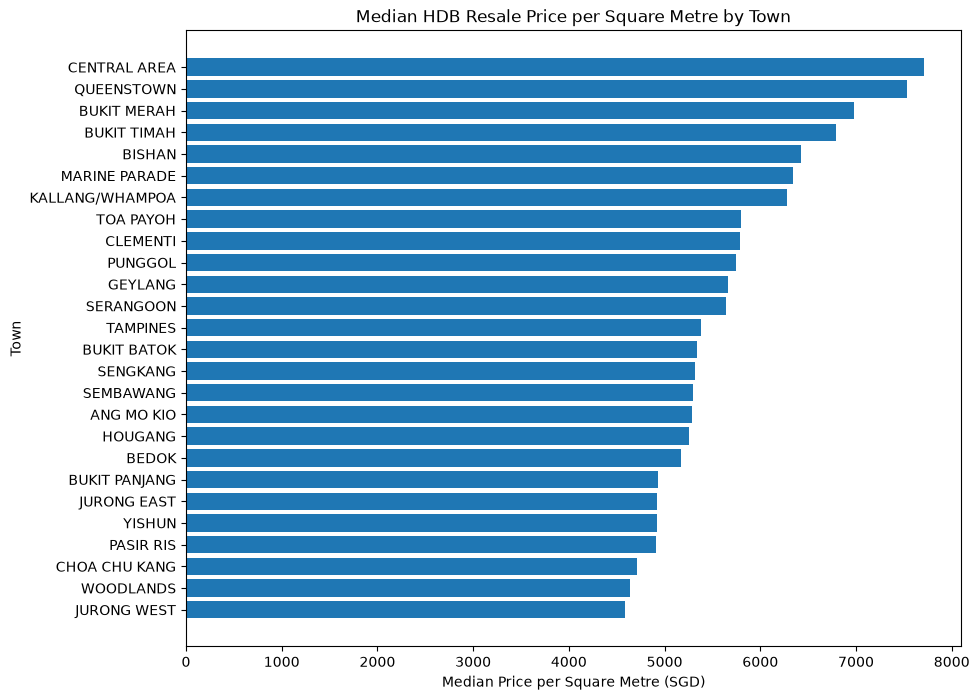

In [20]:
plt.figure(figsize=(10, 8))

plt.barh(
    town_price_per_sqm.index[::-1],
    town_price_per_sqm.values[::-1]
)

plt.title("Median HDB Resale Price per Square Metre by Town")
plt.xlabel("Median Price per Square Metre (SGD)")
plt.ylabel("Town")

plt.show()

**Key finding:** Median price per square metre varies substantially across HDB towns. Central Area has the highest median price per square metre at approximately $7,711, while Jurong West has the lowest at approxiamtely $4,592 in this dataset. Compared with total resale price, this size-adjusted measure ;provides a different view of location-based price differences. This suggests that both location and flat size are important considerations when comparing resale values across towns. 

### 2.6 Transaction Period vs Resale Price 

This analysis examines how median HDB resale prices have changed over the transaction period covered by the dataset. Monthly median resale price is used to reduce the influence of individual high or low-value transactions. 

In [21]:
monthly_prices = (
    df.groupby("month")["resale_price"]
    .median()
)

monthly_prices.head()

month
2017-01-01    405000.0
2017-02-01    415000.0
2017-03-01    415000.0
2017-04-01    408000.0
2017-05-01    410000.0
Name: resale_price, dtype: float64

#### 2.6.1 Monthly Median Resale Price Trend 

A line chart is used to visualize changes in median resale prices over time. Monthly aggregation helps reveal broader market patterns while reducing the influence of individual transactions. 

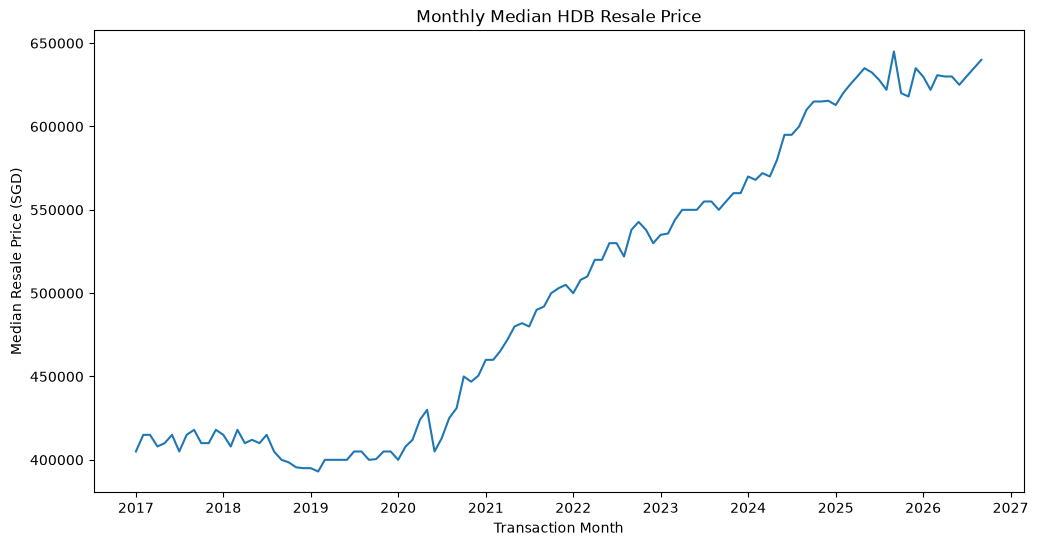

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_prices.index,
    monthly_prices.values
)

plt.title("Monthly Median HDB Resale Price")
plt.xlabel("Transaction Month")
plt.ylabel("Median Resale Price (SGD)")

plt.show()

**Key finding:** Monthly median HDB resale prices show an overall upward trend across the period covered by the dataset. A noticeable decline occurs around 2018 - 2019 before prices resume their upward movement. This indicates that transaction period is an important factor to consider when comparing resale prices as market-wide price levels vary over time. 

#### 2.6.2 Change in Monthly Median Resale Price

The change between the first and latest monthly median resale prices is calculated to provide a simple measure of how the typical transaction price has changed across the dataset period.

In [23]:
first_median = monthly_prices.iloc[0]
latest_median = monthly_prices.iloc[-1]

absolute_change = latest_median - first_median
percentage_change = (absolute_change / first_median) * 100

print("First monthly median:", first_median)
print("Latest monthly median:", latest_median)
print("Absolute change:", absolute_change)
print("Percentage change:", percentage_change)

First monthly median: 405000.0
Latest monthly median: 640000.0
Absolute change: 235000.0
Percentage change: 58.0246913580247


**Key finding:** The monthly median resale price increased from $405,000 in January 2017 to $640,000 in the latest month of the dataset, representing an absolute increase of $235,000 or approximately 58.0%. While the overall trend is upward, the monthly series also shows periods of fluctuation, highlighting the importance of considering transaction period when analysing resale prices.

## 3. Summary of Price Driver Analysis

The analysis explored how HDB resale prices vary across flat characteristics, location, and transaction period.

Key observations include:

- **Floor area:** A moderate positive correlation with resale price (r = 0.563), suggesting that larger flats generally transact at higher prices.
- **Flat type:** Median resale prices differ substantially across flat types.
- **Storey range:** Higher storey ranges are generally associated with higher median resale prices.
- **Remaining lease:** A positive but modest correlation with resale price (r = 0.300).
- **Location:** Median resale prices and price per square metre vary considerably across towns.
- **Transaction period:** Monthly median resale prices increased from $405,000 in January 2017 to $640,000 in the latest month of the dataset, an increase of approximately 58.0%.

These findings highlight that HDB resale prices are associated with multiple factors rather than a single characteristic. Further analysis is needed to examine how these factors interact and whether some relationships remain when other characteristics are considered.

## 4. Comparing Price Patterns Across Flat Types

The previous section examined how individual characteristics are associated with HDB resale prices. However, these relationships may differ across flat types.

This section compares the relationship between floor area and resale price across different flat types to investigate whether larger flats tend to command higher prices within each category.

### 4.1 Comparing Median Floor Area and Resale Price by Flat Type

This analysis compares the median floor area and median resale price across flat types. Using medians helps reduce the influence of unusually high- or low-value transactions and provides a clearer picture of typical resale values for each category.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("../data/hdb_resale_cleaned.csv")
df["month"] = pd.to_datetime(df["month"])

print("Dataset shape:", df.shape)

Dataset shape: (240807, 14)


In [3]:
flat_type_comparison = (
    df.groupby("flat_type")
    .agg(
        median_floor_area_sqm=("floor_area_sqm", "median"),
        median_resale_price=("resale_price", "median")
    )
    .sort_values("median_resale_price", ascending=False)
)

flat_type_comparison

,median_floor_area_sqm,median_resale_price
flat_type,,
MULTI-GENERATION,164.0,848000.0
EXECUTIVE,146.0,728000.0
5 ROOM,117.0,615000.0
4 ROOM,93.0,511000.0
3 ROOM,67.0,360000.0
2 ROOM,47.0,315000.0
1 ROOM,31.0,212500.0


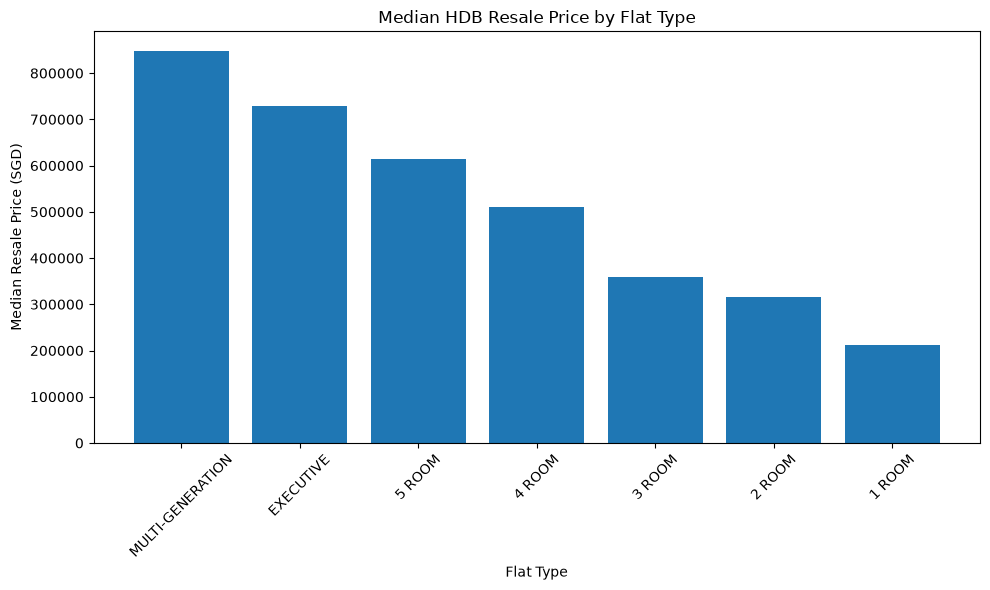

In [4]:

plt.figure(figsize=(10, 6))

plt.bar(
    flat_type_comparison.index,
    flat_type_comparison["median_resale_price"]
)

plt.title("Median HDB Resale Price by Flat Type")
plt.xlabel("Flat Type")
plt.ylabel("Median Resale Price (SGD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4.2 Floor Area and Resale Price Within Flat Types

Although larger flat types generally have higher median resale prices, this comparison does not show whether floor area is similarly associated with resale price within each category.

This section examines the correlation between floor area and resale price separately for each flat type. This helps identify whether the strength of the relationship varies across categories.

In [5]:

correlations = {}

for flat_type, group in df.groupby("flat_type"):
    correlations[flat_type] = group["floor_area_sqm"].corr(
        group["resale_price"]
    )

correlation_by_flat_type = (
    pd.Series(correlations, name="floor_area_price_correlation")
    .sort_values(ascending=False)
)

correlation_by_flat_type


/Users/syaqila/Documents/GitHub/hdb-resale-market-analysis/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/syaqila/Documents/GitHub/hdb-resale-market-analysis/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


EXECUTIVE           0.338508
MULTI-GENERATION    0.268628
3 ROOM              0.221100
2 ROOM              0.122052
5 ROOM              0.009802
4 ROOM             -0.059985
1 ROOM                   NaN
Name: floor_area_price_correlation, dtype: float64

**Key finding:** The relationship between floor area and resale price varies across flat types. Executive flats show the strongest positive correlation (r = 0.339), followed by Multi-Generation flats (r = 0.269) and 3-Room flats (r = 0.221). In contrast, 4-Room and 5-Room flats show correlations close to zero. This suggests that floor area alone does not consistently explain resale price differences within every flat type. Other factors, including location, remaining lease, storey range and transaction period, may also contribute to price variation. The correlation for 1-Room flats could not be calculated from the available data.

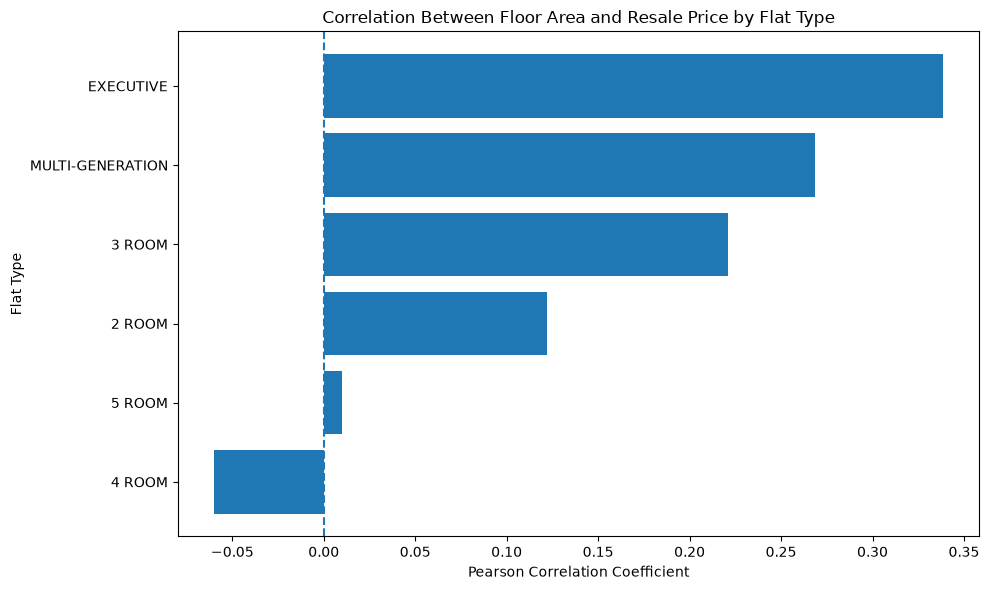

In [ ]:
correlation_chart = correlation_by_flat_type.dropna().sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    correlation_chart.index,
    correlation_chart.values
)

plt.axvline(x=0, linestyle="--")
plt.title("Correlation Between Floor Area and Resale Price by Flat Type")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Flat Type")
plt.tight_layout()
plt.show()

### 4.3 Summary of Flat Type Comparisons

The analysis compared median floor area and resale price across flat types, then examined the correlation between floor area and resale price within each category.

Key observations include:

- **Flat type and price:** Multi-Generation flats had the highest median resale price ($848,000), while 1-Room flats had the lowest ($212,500).
- **Floor area and price:** Flat types with larger median floor areas generally had higher median resale prices.
- **Differences within flat types:** The correlation between floor area and resale price varied across categories. Executive flats showed the strongest positive correlation (r = 0.339), while 4-Room and 5-Room flats had correlations close to zero.
- **Other potential factors:** The variation in correlations suggests that floor area alone may not fully explain resale price differences within each flat type. Location, remaining lease, storey range and transaction period are also worth investigating.

Overall, comparing flats within categories provides additional context beyond examining all transactions together. However, correlation measures linear association and does not establish causation.

## 5. Comparing Resale Prices Across Towns and Flat Types

Median resale prices differ considerably across HDB towns. However, these differences may partly reflect the types and sizes of flats sold in each location.

This section compares resale prices across towns while considering flat type. By examining similar flat categories across different locations, we can develop a more meaningful understanding of geographical price differences.

### 5.1 Median Resale Price by Town and Flat Type

This analysis calculates the median resale price for each combination of HDB town and flat type. Comparing prices within the same flat category helps reduce the influence of differences in flat-type composition across towns.

In [ ]:
town_flat_prices = (
    df.groupby(["town", "flat_type"])["resale_price"]
    .median()
    .unstack()
)

town_flat_prices.head()

flat_type,1 ROOM,2 ROOM,3 ROOM,4 ROOM,5 ROOM,EXECUTIVE,MULTI-GENERATION
town,,,,,,,
ANG MO KIO,NaN,266000.0,350000.0,516000.0,745000.0,920000.0,NaN
BEDOK,NaN,260000.0,340000.0,490000.0,638944.0,825000.0,NaN
BISHAN,NaN,NaN,415000.0,615000.0,825000.0,988444.0,930000.0
BUKIT BATOK,NaN,360000.0,350000.0,515000.0,720000.0,728000.0,NaN
BUKIT MERAH,212500.0,266500.0,385000.0,763000.0,848000.0,750000.0,NaN


### 5.2 Comparing 4-Room Resale Prices Across Towns

This analysis compares median resale prices for 4-Room flats across HDB towns. Focusing on one flat type makes the geographical price differences easier to interpret, although differences in floor area, remaining lease, storey range and transaction period may still affect the results.

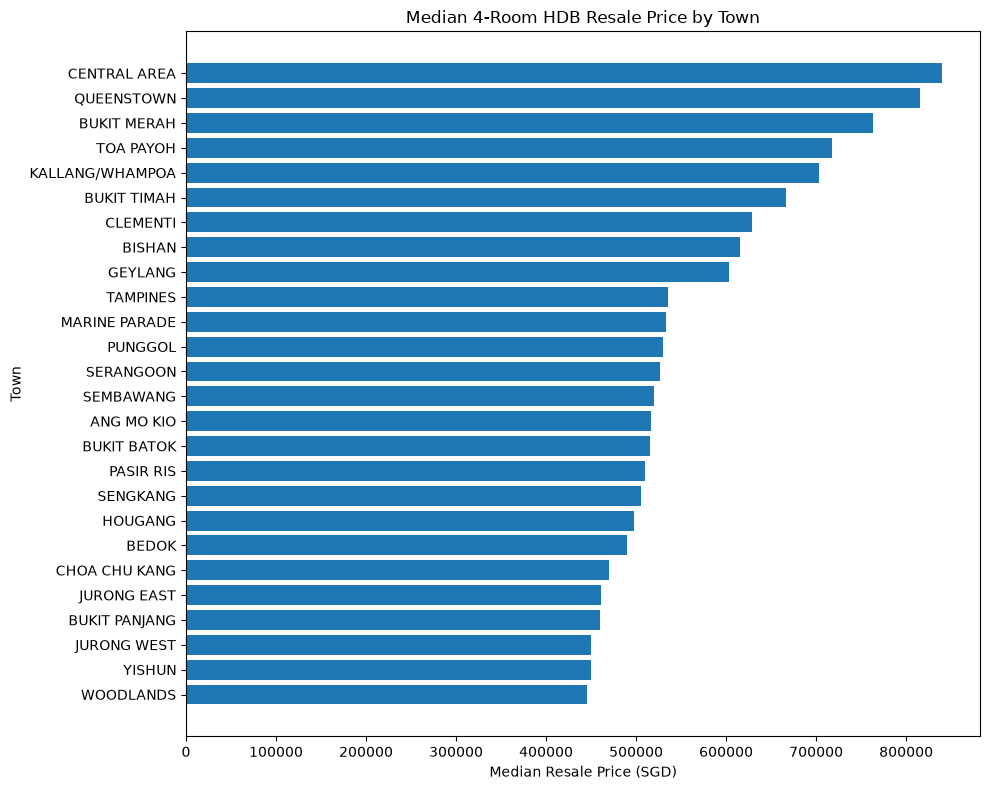

In [8]:
four_room_prices = (
    town_flat_prices["4 ROOM"]
    .dropna()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    four_room_prices.index,
    four_room_prices.values
)

plt.title("Median 4-Room HDB Resale Price by Town")
plt.xlabel("Median Resale Price (SGD)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

In [9]:
print("Town with lowest median 4-Room resale price:")
print(four_room_prices.idxmin(), "-", f"${four_room_prices.min():,.0f}")

print("\nTown with highest median 4-Room resale price:")
print(four_room_prices.idxmax(), "-", f"${four_room_prices.max():,.0f}")

print("\nDifference between highest and lowest:")
print(f"${four_room_prices.max() - four_room_prices.min():,.0f}")

Town with lowest median 4-Room resale price:
WOODLANDS - $445,000

Town with highest median 4-Room resale price:
CENTRAL AREA - $840,000

Difference between highest and lowest:
$395,000


**Key finding:** Median 4-Room HDB resale prices vary substantially across towns. Central Area recorded the highest median resale price at $840,000, while Woodlands recorded the lowest at $445,000, a difference of $395,000. This suggests that geographical location is associated with substantial differences in resale prices, even when comparing the same flat type. However, differences in floor area, remaining lease, storey range and transaction period may also contribute to the observed price gap.

### 5.3 Comparing 3-Room Resale Prices Across Towns

This analysis compares median resale prices for 3-Room flats across HDB towns. Comparing this category with the 4-Room results helps us explore whether geographical price differences are also evident among smaller flat types.

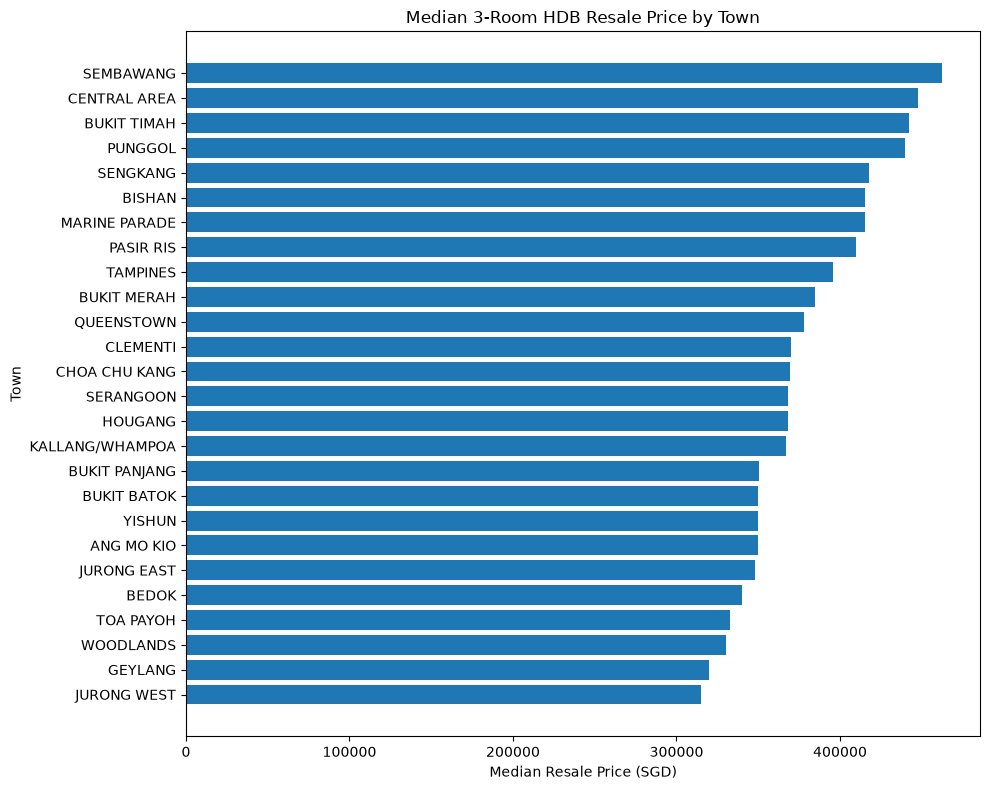

In [10]:
three_room_prices = (
    town_flat_prices["3 ROOM"]
    .dropna()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    three_room_prices.index,
    three_room_prices.values
)

plt.title("Median 3-Room HDB Resale Price by Town")
plt.xlabel("Median Resale Price (SGD)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

In [11]:
print("Town with lowest median 3-Room resale price:")
print(three_room_prices.idxmin(), "-", f"${three_room_prices.min():,.0f}")

print("\nTown with highest median 3-Room resale price:")
print(three_room_prices.idxmax(), "-", f"${three_room_prices.max():,.0f}")

print("\nDifference between highest and lowest:")
print(f"${three_room_prices.max() - three_room_prices.min():,.0f}")

Town with lowest median 3-Room resale price:
JURONG WEST - $315,000

Town with highest median 3-Room resale price:
SEMBAWANG - $462,500

Difference between highest and lowest:
$147,500


**Key finding:** Median 3-Room HDB resale prices vary across towns. Sembawang recorded the highest median resale price at $462,500, while Jurong West recorded the lowest at $315,000, a difference of $147,500. This indicates that geographical price differences are also present among 3-Room flats. The gap is smaller than the $395,000 difference observed for 4-Room flats, although this comparison alone does not establish why the price differences vary between flat types.

### 5.4 Comparing 3-Room and 4-Room Resale Prices Across Towns

This analysis compares median resale prices for 3-Room and 4-Room flats across HDB towns. Displaying both categories together makes it easier to compare geographical price patterns while distinguishing between flat types.

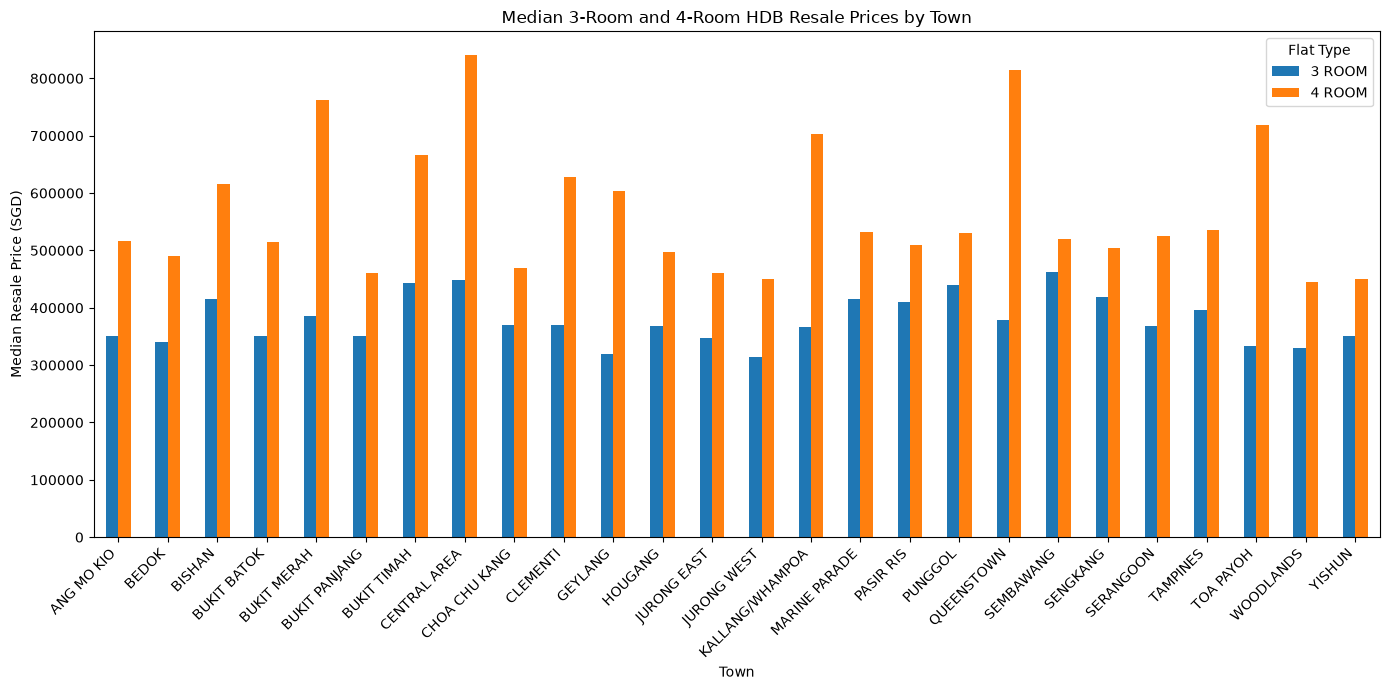

In [12]:
town_comparison = town_flat_prices[["3 ROOM", "4 ROOM"]]

town_comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Median 3-Room and 4-Room HDB Resale Prices by Town")
plt.xlabel("Town")
plt.ylabel("Median Resale Price (SGD)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Flat Type")
plt.tight_layout()
plt.show()

### 5.5 Summary of Town-Level Price Comparisons

This section compared median resale prices across HDB towns, first using overall town-level medians and then comparing prices within specific flat types.

Key observations include:

- **4-Room flats:** Central Area had the highest median resale price at $840,000, while Woodlands had the lowest at $445,000, a difference of $395,000.
- **3-Room flats:** Sembawang had the highest median resale price at $462,500, while Jurong West had the lowest at $315,000, a difference of $147,500.
- **Differences across flat types:** The observed price gap between the highest- and lowest-priced towns was larger for 4-Room flats than for 3-Room flats.
- **Location and other characteristics:** Comparing the same flat type across towns provides more context than comparing overall town medians. However, differences in floor area, remaining lease, storey range and transaction period may still contribute to the observed price differences.

Overall, the analysis highlights geographical variation in HDB resale prices. These results are descriptive and do not isolate the independent effect of location on resale value.

## 6. Comparing Price per Square Metre

Total resale prices can vary because flats differ in size. Price per square metre provides a size-adjusted measure that supports more meaningful comparisons across locations and flat types.

This section examines how median price per square metre varies across HDB towns and flat types, helping identify differences in resale value relative to floor area.

### 6.1 Median Price per Square Metre by Town

This analysis compares the median resale price per square metre across HDB towns. Unlike total resale price, this measure accounts for differences in floor area and provides an additional perspective on geographical price variation.

In [13]:
town_psm = (
    df.groupby("town")["price_per_sqm"]
    .median()
    .sort_values(ascending=True)
)

town_psm

town
JURONG WEST        4591.643312
WOODLANDS          4636.363636
CHOA CHU KANG      4713.114754
PASIR RIS          4905.660377
YISHUN             4923.076923
JURONG EAST        4925.373134
BUKIT PANJANG      4927.521008
BEDOK              5169.230769
HOUGANG            5250.000000
ANG MO KIO         5286.692759
SEMBAWANG          5297.297297
SENGKANG           5315.315315
BUKIT BATOK        5343.283582
TAMPINES           5384.615385
SERANGOON          5640.280262
GEYLANG            5661.086987
PUNGGOL            5741.071429
CLEMENTI           5791.044776
TOA PAYOH          5801.980198
KALLANG/WHAMPOA    6276.923077
MARINE PARADE      6341.463415
BISHAN             6428.571429
BUKIT TIMAH        6792.156120
BUKIT MERAH        6982.758621
QUEENSTOWN         7537.414966
CENTRAL AREA       7710.843373
Name: price_per_sqm, dtype: float64

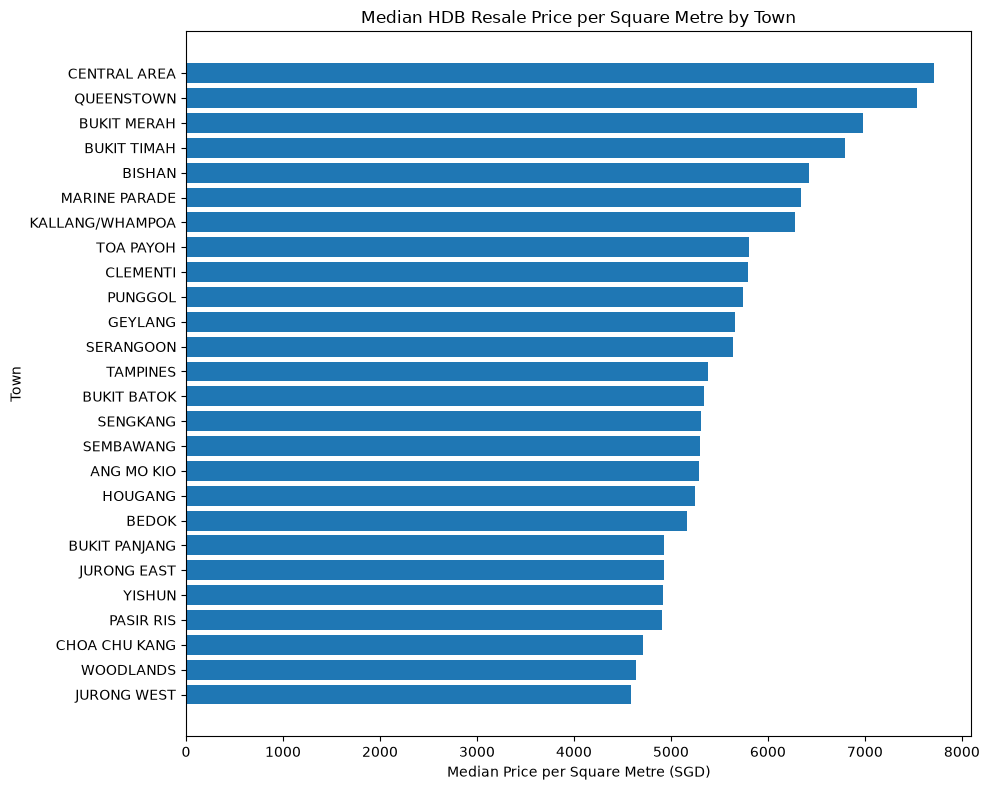

In [14]:
plt.figure(figsize=(10, 8))

plt.barh(
    town_psm.index,
    town_psm.values
)

plt.title("Median HDB Resale Price per Square Metre by Town")
plt.xlabel("Median Price per Square Metre (SGD)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

**Key finding:** Median resale price per square metre varies considerably across HDB towns. Central Area recorded the highest median at approximately $7,711 per square metre, while Jurong West recorded the lowest at approximately $4,592 per square metre. The difference of approximately $3,119 per square metre highlights substantial geographical variation in resale prices relative to floor area. However, price per square metre does not account for other differences between flats, including flat type, remaining lease and storey range.

### 6.2 Median Price per Square Metre by Flat Type

This analysis compares median resale price per square metre across flat types. It provides a size-adjusted perspective on differences between flat categories, complementing the comparison of total median resale prices in Section 4.

In [15]:
flat_type_psm = (
    df.groupby("flat_type")["price_per_sqm"]
    .median()
    .sort_values(ascending=True)
)

flat_type_psm

flat_type
EXECUTIVE           5034.246575
MULTI-GENERATION    5180.969697
5 ROOM              5200.000000
3 ROOM              5327.232877
4 ROOM              5384.615385
2 ROOM              6808.510638
1 ROOM              6854.838710
Name: price_per_sqm, dtype: float64

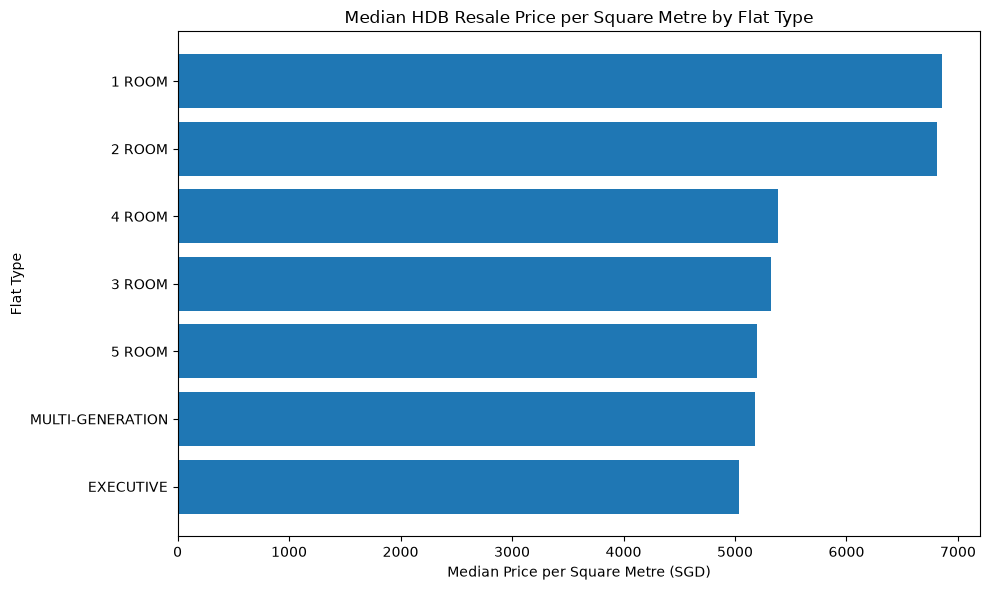

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    flat_type_psm.index,
    flat_type_psm.values
)

plt.title("Median HDB Resale Price per Square Metre by Flat Type")
plt.xlabel("Median Price per Square Metre (SGD)")
plt.ylabel("Flat Type")
plt.tight_layout()
plt.show()

**Key finding:** Median resale price per square metre differs across flat types. 1-Room flats recorded the highest median at approximately $6,855 per square metre, followed by 2-Room flats at approximately $6,809. Executive flats recorded the lowest median at approximately $5,034 per square metre. This contrasts with the total resale price comparison, where larger flat categories generally had higher median prices. The difference highlights why both total resale price and price per square metre are useful when comparing HDB resale values. However, these results may also reflect differences in location, lease duration and the mix of transactions within each flat type.

### 6.3 Summary of Price per Square Metre Analysis

This section examined median resale prices per square metre across HDB towns and flat types to provide a size-adjusted perspective on resale market differences.

Key observations include:

- **Geographical differences:** Central Area had the highest median price per square metre at approximately $7,711, while Jurong West had the lowest at approximately $4,592.
- **Differences across flat types:** 1-Room flats had the highest median price per square metre at approximately $6,855, while Executive flats had the lowest at approximately $5,034.
- **Total price versus price per square metre:** Larger flat types generally had higher total median resale prices, while smaller flat types had higher median prices per square metre.
- **Interpretation:** Price per square metre provides a useful additional measure for comparing resale values, but it does not account for every difference between flats, including location, remaining lease and storey range.

Overall, the analysis demonstrates that conclusions about HDB resale values can differ depending on whether total price or price per square metre is used. Considering both measures provides a more complete descriptive picture of the resale market.

## 7. Analysing Multiple Factors Together

Previous sections examined the relationships between resale prices and individual characteristics, including floor area, flat type, remaining lease, storey range and location.

However, these characteristics may interact or be associated with one another. This section takes a broader view by examining multiple characteristics together, providing additional context for understanding differences in HDB resale prices.

The analysis remains exploratory and descriptive; observed associations should not be interpreted as causal effects.

### 7.1 Reviewing Numerical Variables

Before examining multiple characteristics together, this step reviews the numerical variables available in the dataset. This helps identify suitable inputs for further analysis and confirms that the relevant columns are available.

In [18]:
df[
    [
        "resale_price",
        "floor_area_sqm",
        "remaining_lease_numeric",
        "price_per_sqm",
        "storey_range",
        "flat_type",
        "town"
    ]
].head()

,resale_price,floor_area_sqm,remaining_lease_numeric,price_per_sqm,storey_range,flat_type,town
0,232000.0,44.0,61.333333,5272.727273,10 TO 12,2 ROOM,ANG MO KIO
1,250000.0,67.0,60.583333,3731.343284,01 TO 03,3 ROOM,ANG MO KIO
2,262000.0,67.0,62.416667,3910.447761,01 TO 03,3 ROOM,ANG MO KIO
3,265000.0,68.0,62.000000,3897.058824,04 TO 06,3 ROOM,ANG MO KIO
4,265000.0,67.0,62.416667,3955.223881,01 TO 03,3 ROOM,ANG MO KIO


In [20]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 1.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 3.9 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
import sklearn

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


### 7.2 Preparing Variables for Regression

A multiple linear regression model is used to examine how several flat characteristics are associated with HDB resale prices simultaneously.

The target variable is resale price. The predictors include floor area, remaining lease, storey range, flat type, and town. Categorical variables will be encoded before modelling so that they can be used by the regression algorithm.

Price per square metre is excluded because it is derived from resale price and floor area. Including it as a predictor would introduce target leakage.

In [22]:
target = df["resale_price"]

features = df[
    [
        "floor_area_sqm",
        "remaining_lease_numeric",
        "storey_range",
        "flat_type",
        "town"
    ]
]

print("Target shape:", target.shape)
print("Features shape:", features.shape)

features.head()

Target shape: (240807,)
Features shape: (240807, 5)


,floor_area_sqm,remaining_lease_numeric,storey_range,flat_type,town
0,44.0,61.333333,10 TO 12,2 ROOM,ANG MO KIO
1,67.0,60.583333,01 TO 03,3 ROOM,ANG MO KIO
2,67.0,62.416667,01 TO 03,3 ROOM,ANG MO KIO
3,68.0,62.000000,04 TO 06,3 ROOM,ANG MO KIO
4,67.0,62.416667,01 TO 03,3 ROOM,ANG MO KIO


### 7.3 Splitting the Data

The dataset is divided into training and testing sets using an 80:20 split. The training set is used to fit the regression model, while the testing set is reserved for evaluating its predictive performance on unseen data.

A fixed random state is used to make the results reproducible.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (192645, 5)
Testing features: (48162, 5)
Training target: (192645,)
Testing target: (48162,)


### 7.4 Encoding Categorical Variables

Storey range, flat type, and town are categorical variables. One-hot encoding converts these categories into numerical indicator columns that can be used by a linear regression model.

The encoder will be fitted on the training data and applied to the testing data using a pipeline. This helps prevent information from the testing set from leaking into model training.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = [
    "floor_area_sqm",
    "remaining_lease_numeric"
]

categorical_features = [
    "storey_range",
    "flat_type",
    "town"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (192645, 52)
Encoded testing shape: (48162, 52)


### 7.5 Training the Multiple Linear Regression Model

A multiple linear regression model is fitted using the training dataset. The model examines the combined relationship between resale prices and the selected predictors: floor area, remaining lease, storey range, flat type, and town.

The fitted model will then be used to generate predictions for the separate testing dataset.

In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_encoded, y_train)

print("Model training completed successfully.")

Model training completed successfully.


### 7.6 Evaluating Model Performance

The trained model is used to predict resale prices for the testing dataset. Its performance is evaluated using three metrics:

- **Mean Absolute Error (MAE):** The average absolute difference between predicted and actual resale prices, measured in Singapore dollars.
- **Root Mean Squared Error (RMSE):** A measure of prediction error that gives greater weight to larger errors.
- **R-squared (R²):** The proportion of variation in resale prices explained by the model on the testing dataset.

Together, these metrics provide an initial assessment of the model's predictive performance on unseen transactions.

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test_encoded)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")

Mean Absolute Error (MAE): $94,051.71
Root Mean Squared Error (RMSE): $115,857.67
R-squared (R²): 0.6362


**Key finding:** The multiple linear regression model achieved an R² of 0.6362 on the testing dataset, explaining approximately 63.6% of the variation in resale prices. The model recorded a mean absolute error (MAE) of approximately $94,052 and a root mean squared error (RMSE) of approximately $115,858.

These results suggest that floor area, remaining lease, storey range, flat type, and town collectively provide useful information for predicting resale prices. However, the prediction errors indicate that these variables do not fully capture the factors influencing individual transaction prices. The model therefore serves as a baseline for further evaluation and improvement, rather than a precise property valuation tool.

In [27]:
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

comparison["Prediction Error"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

comparison.head(10).round(2)

,Actual Price,Predicted Price,Prediction Error
127347,595000.0,514087.34,80912.66
116059,750000.0,643983.95,106016.05
144750,468000.0,468045.67,-45.67
239732,405000.0,269517.34,135482.66
126369,458000.0,419811.92,38188.08
168154,620000.0,642704.13,-22704.13
240503,596888.0,450048.63,146839.37
115522,465000.0,525545.46,-60545.46
79192,350000.0,409887.61,-59887.61
157845,580000.0,534717.25,45282.75


In [28]:
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

comparison["Prediction Error"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

comparison.head(10).round(2)

,Actual Price,Predicted Price,Prediction Error
0,595000.0,514087.34,80912.66
1,750000.0,643983.95,106016.05
2,468000.0,468045.67,-45.67
3,405000.0,269517.34,135482.66
4,458000.0,419811.92,38188.08
5,620000.0,642704.13,-22704.13
6,596888.0,450048.63,146839.37
7,465000.0,525545.46,-60545.46
8,350000.0,409887.61,-59887.61
9,580000.0,534717.25,45282.75


### 7.7 Visualising Actual vs Predicted Resale Prices

A scatter plot compares the actual resale prices with the prices predicted by the regression model. A reference line represents perfect predictions, where predicted prices equal actual prices.

Points closer to this line indicate more accurate predictions, while points farther away indicate larger prediction errors.

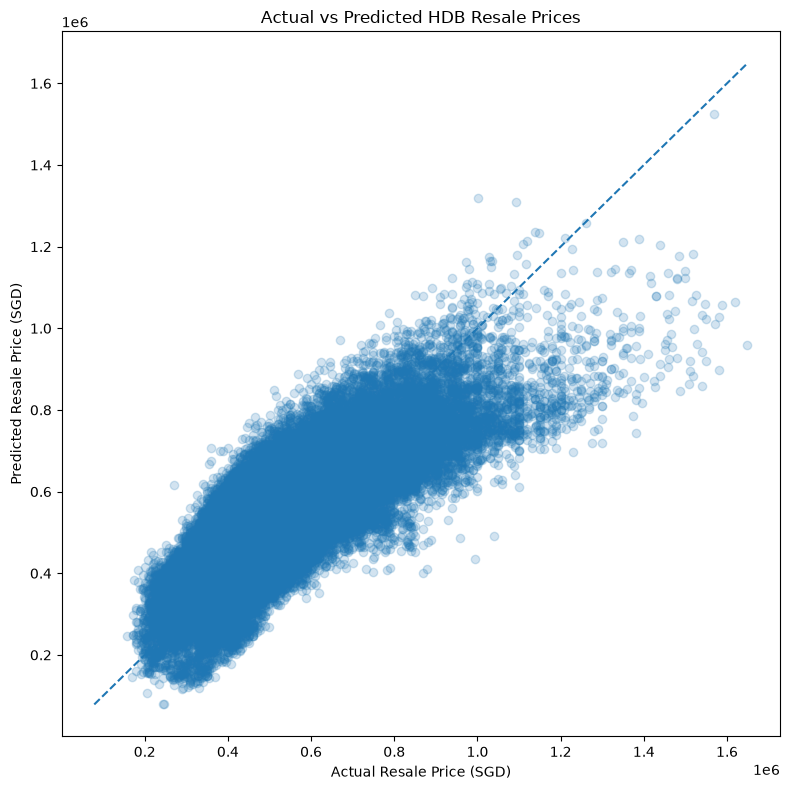

In [29]:
plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred, alpha=0.2)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted HDB Resale Prices")
plt.xlabel("Actual Resale Price (SGD)")
plt.ylabel("Predicted Resale Price (SGD)")
plt.tight_layout()
plt.show()

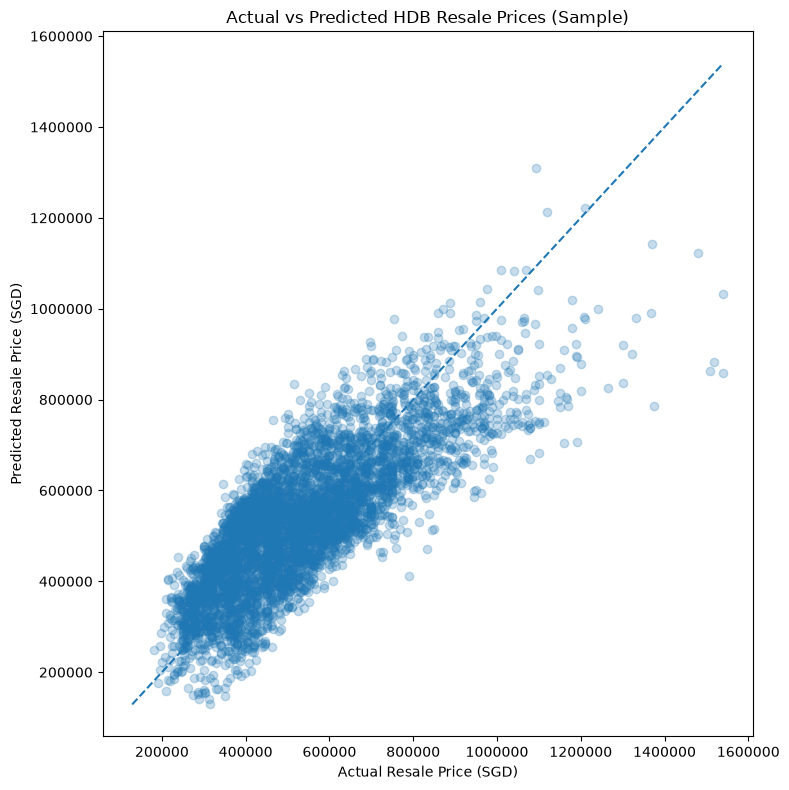

In [30]:
sample = comparison.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(8, 8))

plt.scatter(
    sample["Actual Price"],
    sample["Predicted Price"],
    alpha=0.25
)

min_price = min(
    sample["Actual Price"].min(),
    sample["Predicted Price"].min()
)

max_price = max(
    sample["Actual Price"].max(),
    sample["Predicted Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted HDB Resale Prices (Sample)")
plt.xlabel("Actual Resale Price (SGD)")
plt.ylabel("Predicted Resale Price (SGD)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

**Key finding:** The actual-versus-predicted scatter plot shows that the model captures some of the overall variation in HDB resale prices, but its predictions do not consistently match actual transaction prices. The spread of points around the reference line indicates prediction errors, with some transactions being overpredicted and others underpredicted. This is consistent with the model's R² of 0.6362 and MAE of approximately $94,052. The results suggest that the selected flat characteristics provide useful predictive information, although additional factors or more flexible modelling approaches may improve performance.

### 7.8 Interpreting Regression Coefficients

Regression coefficients describe how each model feature is associated with the predicted resale price, while holding the other model features constant.

The numerical variables were standardised, so their coefficients represent the estimated change in predicted resale price associated with a one-standard-deviation increase in the corresponding variable. The categorical variables were one-hot encoded, so their coefficients represent differences relative to reference categories.

These coefficients describe associations within the fitted model and should not be interpreted as causal effects.


In [31]:
feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_
})

coefficients.head(10)

,Feature,Coefficient
0,num__floor_area_sqm,93981.182790
1,num__remaining_lease_numeric,66347.617363
2,cat__storey_range_01 TO 03,-179478.204330
3,cat__storey_range_04 TO 06,-161833.734331
4,cat__storey_range_07 TO 09,-148265.801394
5,cat__storey_range_10 TO 12,-137942.272854
6,cat__storey_range_13 TO 15,-124725.727553
7,cat__storey_range_16 TO 18,-100795.101900
8,cat__storey_range_19 TO 21,-67038.093522
9,cat__storey_range_22 TO 24,-53406.468621


### 7.8 Interpreting Regression Coefficients

Regression coefficients describe how each feature is associated with the model's predicted resale price, holding the other features constant.

The numerical variables are standardised, so their coefficients represent the estimated change in predicted resale price associated with a one-standard-deviation increase in the corresponding variable. Categorical variables are one-hot encoded, with a reference category omitted so that the remaining coefficients can be interpreted relative to that category.

These coefficients describe associations within the fitted model and should not be interpreted as causal effects.

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features
        )
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

model = LinearRegression()
model.fit(X_train_encoded, y_train)

print("Updated model trained successfully.")
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Updated model trained successfully.
Encoded training shape: (192645, 49)
Encoded testing shape: (48162, 49)


In [33]:
y_pred = model.predict(X_test_encoded)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")

Mean Absolute Error (MAE): $94,051.74
Root Mean Squared Error (RMSE): $115,857.76
R-squared (R²): 0.6362


In [34]:
feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
).head(15)

,Feature,Coefficient,Absolute Coefficient
17,cat__storey_range_49 TO 51,428852.010537,428852.010537
16,cat__storey_range_46 TO 48,383174.761306,383174.761306
15,cat__storey_range_43 TO 45,380369.358598,380369.358598
14,cat__storey_range_40 TO 42,302465.546652,302465.546652
13,cat__storey_range_37 TO 39,245531.605962,245531.605962
12,cat__storey_range_34 TO 36,244390.154886,244390.154886
11,cat__storey_range_31 TO 33,244255.736430,244255.736430
23,cat__flat_type_MULTI-GENERATION,213150.894691,213150.894691
10,cat__storey_range_28 TO 30,205119.480979,205119.480979
29,cat__town_BUKIT TIMAH,203964.446018,203964.446018


### 7.9 Visualising the Largest Regression Coefficients

The largest regression coefficients by absolute magnitude are visualised to highlight features associated with larger changes in the model's predicted resale prices.

Categorical coefficients are interpreted relative to their respective reference categories. Numerical coefficients represent the estimated change associated with a one-standard-deviation increase in the standardised feature. Because these feature types have different interpretations, coefficient magnitudes should be compared cautiously.

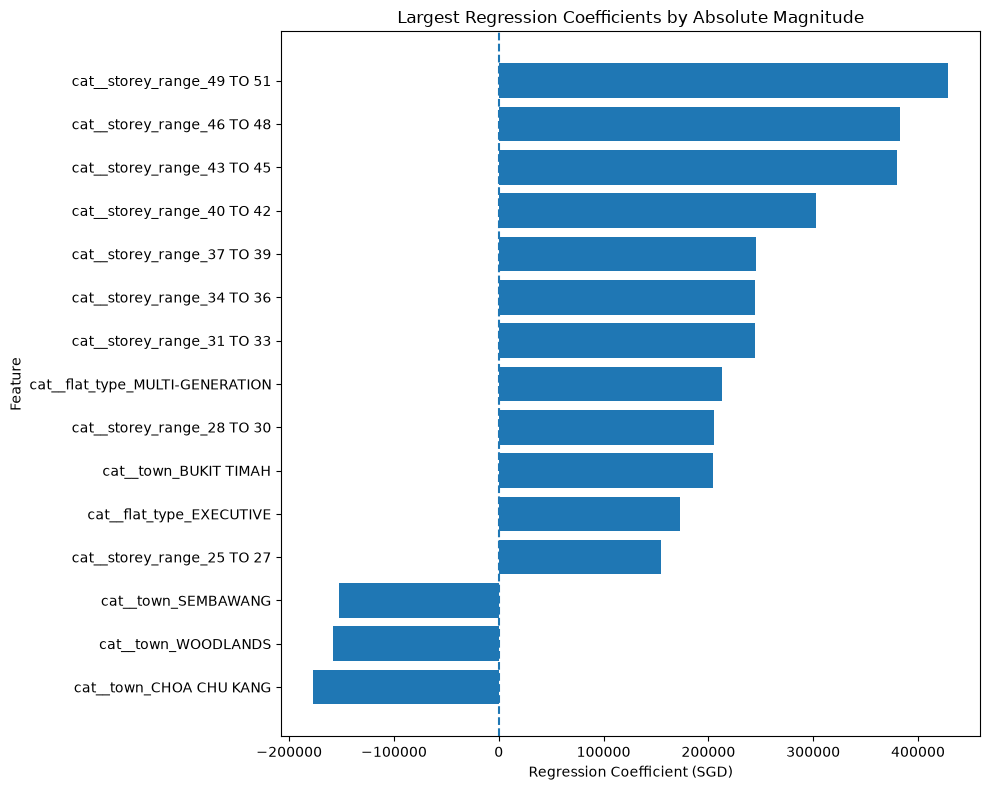

In [35]:
top_coefficients = (
    coefficients
    .sort_values("Absolute Coefficient", ascending=False)
    .head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(x=0, linestyle="--")
plt.title("Largest Regression Coefficients by Absolute Magnitude")
plt.xlabel("Regression Coefficient (SGD)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Key finding:** The regression coefficients indicate that storey range, flat type, and town are associated with differences in predicted HDB resale prices, after accounting for the other included features. The largest positive storey-range coefficients occur among the highest storey categories, while some towns have negative coefficients relative to the reference town.

These results suggest that location and flat characteristics provide complementary information when estimating resale prices. However, categorical coefficients depend on their reference categories, and the model does not account for every factor affecting transaction prices. The findings should therefore be interpreted as model-based associations rather than causal effects.

### 7.10 Summary of Multiple-Factor Analysis

The multiple linear regression model examined the combined associations between HDB resale prices and floor area, remaining lease, storey range, flat type, and town.

On the testing dataset, the model achieved an R² of 0.6362, an MAE of approximately $94,052, and an RMSE of approximately $115,858. These results indicate that the selected features explain a meaningful proportion of variation in resale prices, although substantial prediction errors remain.

The coefficient analysis suggests that storey range, flat type, and location are associated with differences in predicted prices when the other included features are held constant. However, these relationships may reflect differences in other property characteristics and market conditions that are not fully captured by the model.

Overall, the analysis demonstrates the value of considering multiple characteristics together rather than interpreting each factor in isolation. The regression model provides a useful baseline for further analysis, but its predictions should not be treated as precise property valuations.

## 8. Comparing Against a Baseline Model

A regression model's performance is more meaningful when compared with a simple baseline. This section evaluates whether the multiple linear regression model improves prediction accuracy over a model that predicts the same resale price for every transaction.

The baseline provides a reference point for assessing the value of including flat characteristics and location in the prediction model.

### 8.1 Establishing a Median-Price Baseline

The baseline model predicts the median resale price from the training dataset for every transaction in the testing dataset. This provides a simple benchmark against which the multiple linear regression model can be evaluated.

Using the training set to calculate the baseline prevents information from the testing set from influencing the benchmark.

In [36]:
baseline_prediction = y_train.median()

y_baseline_pred = np.full(
    shape=len(y_test),
    fill_value=baseline_prediction
)

baseline_mae = mean_absolute_error(
    y_test,
    y_baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_baseline_pred)
)

baseline_r2 = r2_score(
    y_test,
    y_baseline_pred
)

print(f"Baseline predicted price: ${baseline_prediction:,.2f}")
print(f"Baseline MAE: ${baseline_mae:,.2f}")
print(f"Baseline RMSE: ${baseline_rmse:,.2f}")
print(f"Baseline R-squared: {baseline_r2:.4f}")

Baseline predicted price: $503,000.00
Baseline MAE: $149,231.49
Baseline RMSE: $194,919.97
Baseline R-squared: -0.0298


### 8.2 Comparing Model Performance

The multiple linear regression model outperformed the median-price baseline across all three evaluation metrics.

The baseline achieved an MAE of approximately $149,231 and an RMSE of approximately $194,920, compared with $94,052 and $115,858 respectively for the regression model. This represents an approximately 37.0% reduction in MAE and a 40.6% reduction in RMSE.

The regression model achieved an R² of 0.6362, while the baseline recorded an R² of -0.0298. These results indicate that incorporating floor area, remaining lease, storey range, flat type, and town provides substantially more predictive information than assigning the same median price to every transaction.

Although the regression model performs better than the baseline, its remaining prediction errors are substantial. It should therefore be treated as a useful analytical benchmark rather than a precise property valuation tool.

In [37]:
print("Dataset rows:", len(df))
print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))
print()

print("Regression model")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print()

print("Median-price baseline")
print(f"MAE:  ${baseline_mae:,.2f}")
print(f"RMSE: ${baseline_rmse:,.2f}")
print(f"R²:   {baseline_r2:.4f}")

Dataset rows: 240807
Training transactions: 192645
Testing transactions: 48162

Regression model
MAE:  $94,051.74
RMSE: $115,857.76
R²:   0.6362

Median-price baseline
MAE:  $149,231.49
RMSE: $194,919.97
R²:   -0.0298


## 9. Overall Conclusion

This notebook examined the relationships between HDB resale prices and several flat characteristics, including floor area, remaining lease, storey range, flat type, location, and transaction period.

The exploratory analysis identified substantial price differences across flat types and towns, a moderate positive correlation between floor area and resale price, and an overall upward trend in monthly median resale prices across the dataset period.

The multiple linear regression model achieved an R² of 0.6362, an MAE of approximately $94,052, and an RMSE of approximately $115,858 on the testing dataset. It outperformed the median-price baseline, reducing MAE by approximately 37.0% and RMSE by approximately 40.6%.

These findings suggest that combining flat characteristics and location provides useful information for understanding and predicting resale prices. However, substantial prediction errors remain, and the analysis does not establish causal relationships. The model is best treated as a baseline for further investigation rather than a property valuation tool.

Future work could explore nonlinear models, additional property and location features, and time-aware validation to assess whether predictive performance can be improved further.